# Network Analysis with NetworkX (Improved Version)

Modified from: Platt, E. (2019). *Network Science with Python and NetworkX: Quick Start Guide.*

References: https://networkx.org/ and https://networkx.org/documentation/stable/tutorial.html

**What improved compared with the original notebook**

| Area | Original | Improved |
|---|---|---|
| Portability | Required Google Drive and `%pushd` | Works in Colab, locally and when opened from GitHub; reads the data from a GitHub raw link, with a local-file fallback |
| Missing data | Crashed if the `.gexf` file was absent | Clear warning plus a small demo graph so every cell still runs |
| Reproducibility | `hash()` seed (changes every session) and seeding done twice | One fixed `SEED`; layouts also receive the seed |
| Structure | Repeated plotting code, `G` reused for 5 different graphs | Helper functions and descriptive variable names |
| Readability | Imports scattered, few explanations | All imports at top, docstrings, section headings |
| Plot output | No `plt.show()`, no titles | Every plot has a title and is shown explicitly |

## 1. Setup

In [31]:
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

%matplotlib inline

# --- Reproducibility -------------------------------------------------------
# Python's built-in hash() of a string changes every session, so a fixed
# integer is used instead. The same seed gives the same layouts every run.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Plot style ------------------------------------------------------------
plt.rcParams.update({
    "figure.figsize": (7.5, 7.5),
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.top": False,
    "axes.spines.bottom": False,
})

IN_COLAB = "google.colab" in sys.modules
print(f"NetworkX {nx.__version__} | Running in Colab: {IN_COLAB}")

NetworkX 3.7 | Running in Colab: True


### Where the data comes from

The data file `klas12b-net-1.gexf` is read **directly from GitHub** (raw link), so the notebook runs for anyone who opens it from the repository, with no upload needed.
If GitHub cannot be reached, the notebook looks for a local copy next to the notebook (or in Colab's `/content`). If that also fails, it warns you and uses a small demo graph.

In [32]:
import io
import urllib.request


DATA_FILE = "klas12b-net-1.gexf"
GITHUB_URL = "https://raw.githubusercontent.com/maxiangt/MSSP607/refs/heads/main/Modules/Week_10/" + DATA_FILE


def read_gexf_from_github(url):
    """Download a .gexf file from `url` and return it as a NetworkX graph."""
    with urllib.request.urlopen(url, timeout=20) as response:
        return nx.read_gexf(io.BytesIO(response.read()), node_type=int)


def find_local_file(filename):
    """Return the Path of `filename` in the current folder or /content, otherwise None."""
    for folder in (Path.cwd(), Path("/content")):
        if (folder / filename).exists():
            return folder / filename
    return None

## 2. Creating a network

An undirected, unweighted graph is created with `nx.Graph()`. Nodes can be added one at a time (`add_node`) or all at once (`add_nodes_from`); the same applies to edges.

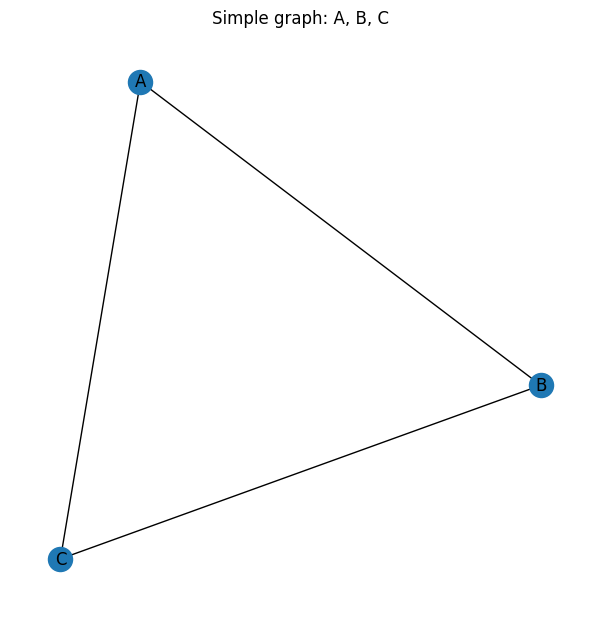

In [33]:
simple_graph = nx.Graph()
simple_graph.add_node("A")
simple_graph.add_nodes_from(["B", "C"])

simple_graph.add_edge("A", "B")
simple_graph.add_edges_from([("B", "C"), ("A", "C")])

plt.figure()
nx.draw_networkx(simple_graph, pos=nx.spring_layout(simple_graph, seed=SEED))
plt.title("Simple graph: A, B, C")
plt.show()

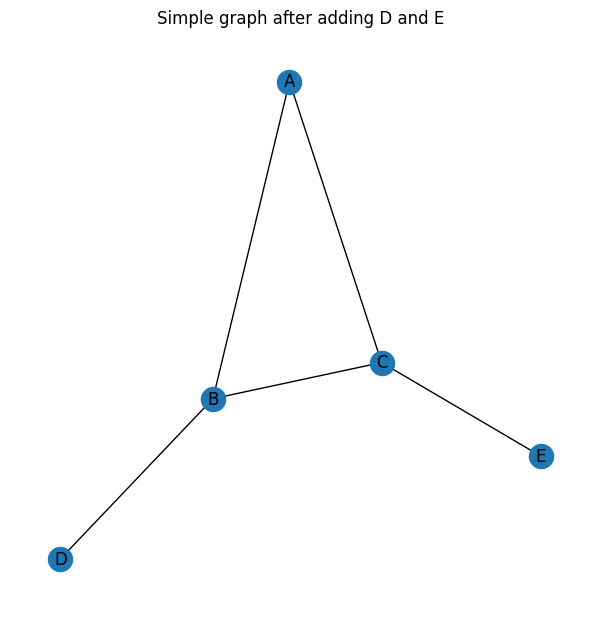

In [34]:
# Adding edges to a new node (D) or an existing node (C) creates the missing nodes automatically.
simple_graph.add_edges_from([("B", "D"), ("C", "E")])

plt.figure()
nx.draw_networkx(simple_graph, pos=nx.spring_layout(simple_graph, seed=SEED))
plt.title("Simple graph after adding D and E")
plt.show()

## 3. The Graph class: undirected networks (Zachary's Karate Club)

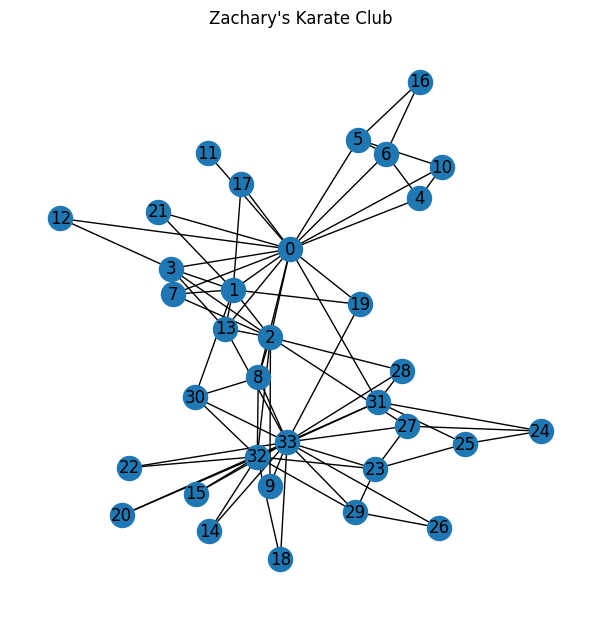

Nodes: 34 | Edges: 78
First 10 nodes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
First 10 edges: [(0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 10), (0, 11)]


In [35]:
karate = nx.karate_club_graph()
karate_pos = nx.spring_layout(karate, k=0.3, seed=SEED)

plt.figure()
nx.draw_networkx(karate, karate_pos)
plt.title("Zachary's Karate Club")
plt.show()

print(f"Nodes: {karate.number_of_nodes()} | Edges: {karate.number_of_edges()}")
print("First 10 nodes:", list(karate.nodes)[:10])
print("First 10 edges:", list(karate.edges)[:10])

### Checking for nodes and edges

In [36]:
mr_hi, john_a, wild_goose = 0, 33, 1337   # Mr. Hi, John A., and a node that does not exist

for node in (mr_hi, wild_goose):
    print(f"Node {node} in graph: {node in karate} (has_node: {karate.has_node(node)})")

print("Neighbors of Mr. Hi:", list(karate.neighbors(mr_hi)))

for pair in [(mr_hi, 1), (mr_hi, john_a)]:
    print(f"Edge {pair} exists: {karate.has_edge(*pair)}")

Node 0 in graph: True (has_node: True)
Node 1337 in graph: False (has_node: False)
Neighbors of Mr. Hi: [1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 17, 19, 21, 31]
Edge (0, 1) exists: True
Edge (0, 33) exists: False


### Adding attributes to nodes and edges

Each member belongs to one of two clubs (0 or 1) after the club split. The attribute is stored on every node.

In [37]:
member_club = [
    0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
    0, 0, 0, 0, 1, 1, 0, 0, 1, 0,
    1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
    1, 1, 1, 1,
]

# Safety check: one club label per node, otherwise the mapping would be wrong.
assert len(member_club) == karate.number_of_nodes(), "member_club length must match node count"

for node_id in karate.nodes:
    karate.nodes[node_id]["club"] = member_club[node_id]

print("Mr. Hi:", karate.nodes[mr_hi])
print("John A.:", karate.nodes[john_a])

Mr. Hi: {'club': 0}
John A.: {'club': 1}


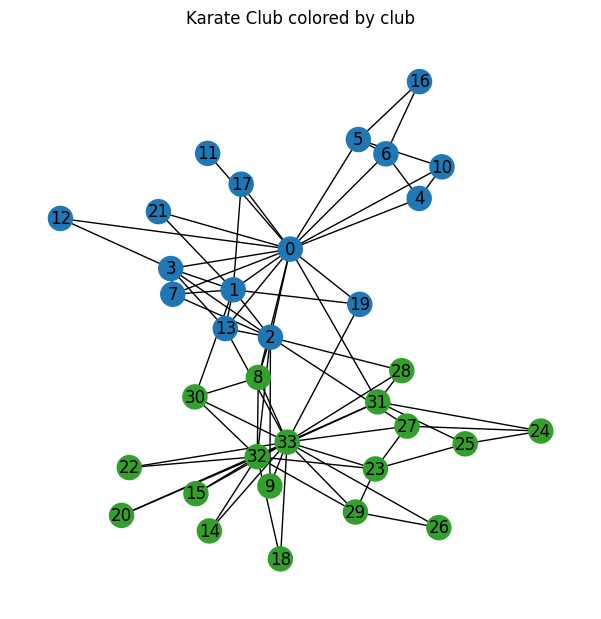

In [38]:
CLUB_COLORS = {0: "#1f78b4", 1: "#33a02c"}
node_colors = [CLUB_COLORS[karate.nodes[v]["club"]] for v in karate]

plt.figure()
nx.draw_networkx(karate, karate_pos, node_color=node_colors)
plt.title("Karate Club colored by club")
plt.show()

An edge is **internal** if both members are in the same club and **external** otherwise. Solid lines are internal, dashed lines external.

Internal edges: 68 | External edges: 10


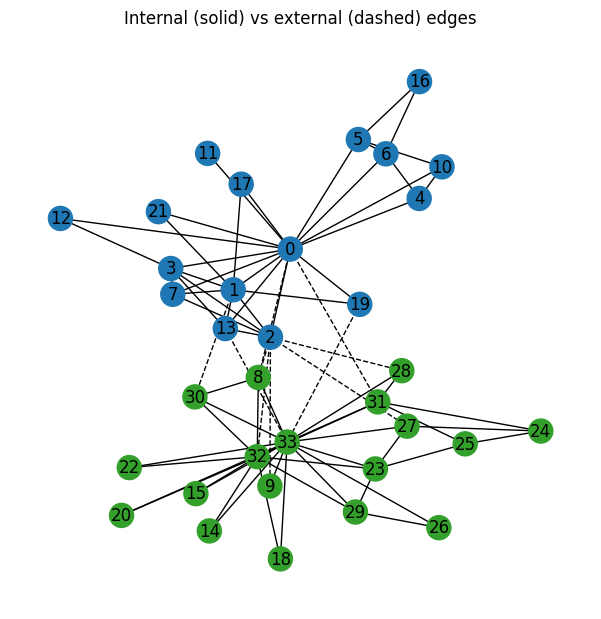

In [39]:
for v, w in karate.edges:
    karate.edges[v, w]["internal"] = karate.nodes[v]["club"] == karate.nodes[w]["club"]

internal_edges = [e for e in karate.edges if karate.edges[e]["internal"]]
external_edges = [e for e in karate.edges if not karate.edges[e]["internal"]]
print(f"Internal edges: {len(internal_edges)} | External edges: {len(external_edges)}")


def draw_club_network(graph, pos, node_colors, title, **edge_kwargs):
    """Draw nodes and labels, with internal edges solid and external edges dashed."""
    nx.draw_networkx_nodes(graph, pos, node_color=node_colors)
    nx.draw_networkx_labels(graph, pos)
    nx.draw_networkx_edges(graph, pos, edgelist=internal_edges, **edge_kwargs)
    nx.draw_networkx_edges(graph, pos, edgelist=external_edges, style="dashed", **edge_kwargs)
    plt.title(title)


plt.figure()
draw_club_network(karate, karate_pos, node_colors, "Internal (solid) vs external (dashed) edges")
plt.show()

### Adding edge weights

NetworkX algorithms such as shortest paths, flow and clustering can use edge weights.
Here the **tie strength** of an edge is 1 plus the number of neighbors the two endpoints share.

In [40]:
def tie_strength(graph, v, w):
    """Return 1 + the number of common neighbors of nodes v and w."""
    return 1 + len(set(graph.neighbors(v)) & set(graph.neighbors(w)))


for v, w in karate.edges:
    karate.edges[v, w]["weight"] = tie_strength(karate, v, w)

edge_weights = [karate.edges[v, w]["weight"] for v, w in karate.edges]
print(f"Weights range from {min(edge_weights)} to {max(edge_weights)}")

weighted_pos = nx.spring_layout(karate, pos=karate_pos, k=0.3, weight="weight", seed=SEED)

Weights range from 1 to 11


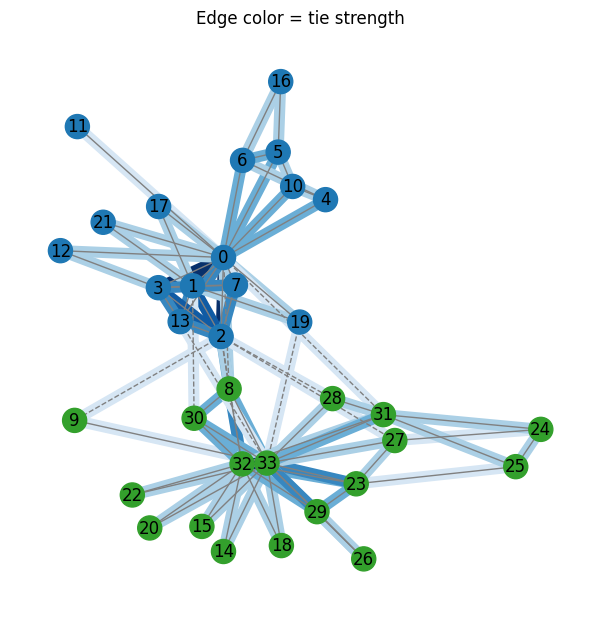

In [41]:
plt.figure()
nx.draw_networkx(
    karate, weighted_pos, width=8, node_color=node_colors,
    edge_color=edge_weights, edge_vmin=0, edge_vmax=6, edge_cmap=plt.cm.Blues,
)
# Draw gray solid/dashed lines on top to keep the internal/external information.
nx.draw_networkx_edges(karate, weighted_pos, edgelist=internal_edges, edge_color="gray")
nx.draw_networkx_edges(karate, weighted_pos, edgelist=external_edges, edge_color="gray", style="dashed")
plt.title("Edge color = tie strength")
plt.show()

## 4. Basic graph statistics (extra, short)

In [42]:
degree_centrality = nx.degree_centrality(karate)
top_members = sorted(degree_centrality, key=degree_centrality.get, reverse=True)[:3]
print("Most connected members (degree centrality):")
for member in top_members:
    print(f"  Node {member}: {degree_centrality[member]:.3f}")
print(f"Average clustering coefficient: {nx.average_clustering(karate):.3f}")

Most connected members (degree centrality):
  Node 33: 0.515
  Node 0: 0.485
  Node 32: 0.364
Average clustering coefficient: 0.571


## 5. The DiGraph class: when direction matters

The classroom network is stored in a GEXF file on GitHub (see Section 1). If it cannot be loaded, a small random directed graph is used so the rest of the notebook still runs.

Data source: GitHub | directed: True | nodes: 26 | edges: 91


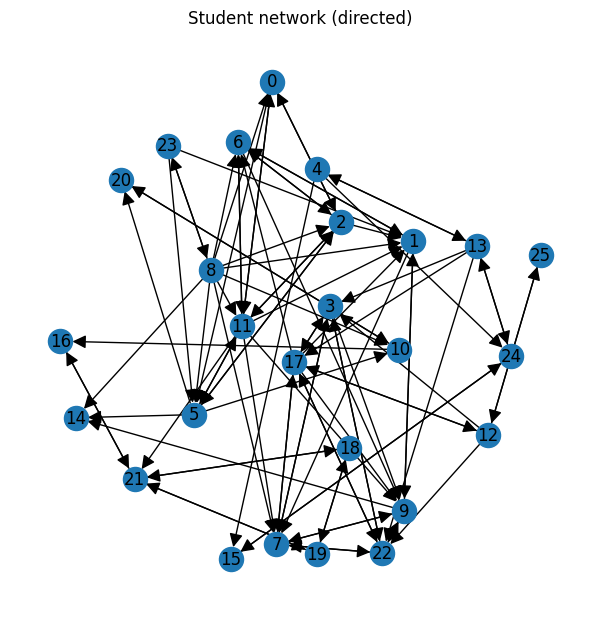

In [43]:
def load_student_network():
    """Return (graph, source). Tries GitHub, then a local file, then a demo graph."""
    try:
        return read_gexf_from_github(GITHUB_URL), "GitHub"
    except Exception as error:
        print(f"Could not read from GitHub ({error}). Trying a local file...")

    local_path = find_local_file(DATA_FILE)
    if local_path is not None:
        try:
            return nx.read_gexf(local_path, node_type=int), f"local file ({local_path})"
        except Exception as error:
            print(f"Could not read {local_path}: {error}")

    print("WARNING: using a random demo DiGraph (12 nodes) instead of the class data.")
    return nx.gnp_random_graph(12, 0.2, seed=SEED, directed=True), "demo graph"


student_graph, data_source = load_student_network()
print(f"Data source: {data_source} | directed: {student_graph.is_directed()} | "
      f"nodes: {student_graph.number_of_nodes()} | edges: {student_graph.number_of_edges()}")

student_pos = nx.spring_layout(student_graph, k=1.5, seed=SEED)
plt.figure()
nx.draw_networkx(student_graph, student_pos, arrowsize=20)
plt.title("Student network (directed)")
plt.show()

In [44]:
focus_node = 0
if focus_node not in student_graph:
    focus_node = next(iter(student_graph.nodes))   # fall back to the first available node

print(f"Node {focus_node}")
print("  neighbors   :", list(student_graph.neighbors(focus_node)))     # same as successors in a DiGraph
print("  successors  :", list(student_graph.successors(focus_node)))    # nodes it points to
print("  predecessors:", list(student_graph.predecessors(focus_node)))  # nodes pointing to it

Node 0
  neighbors   : [2, 5, 11]
  successors  : [2, 5, 11]
  predecessors: [2, 11, 8]


Edges (either direction): 63 | Mutual edges: 28


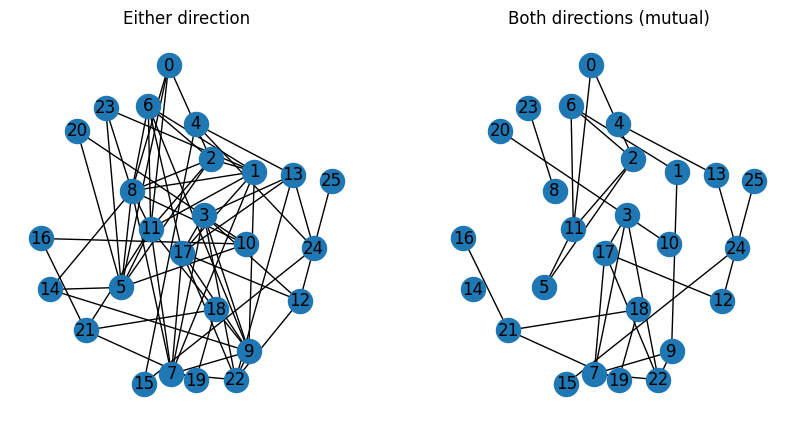

In [45]:
# "either" keeps an edge if at least one direction exists; "both" keeps only reciprocal (mutual) edges.
graph_either = student_graph.to_undirected()
graph_both = student_graph.to_undirected(reciprocal=True)
print(f"Edges (either direction): {graph_either.number_of_edges()} | Mutual edges: {graph_both.number_of_edges()}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, graph, title in zip(axes, (graph_either, graph_both), ("Either direction", "Both directions (mutual)")):
    nx.draw_networkx(graph, student_pos, ax=ax)
    ax.set_title(title)
plt.show()

## 6. MultiGraph and MultiDiGraph: parallel edges

A `MultiGraph` allows several edges between the same pair of nodes. Example: the seven bridges of Königsberg.

In [46]:
bridges = [
    ("North Bank", "Kneiphof", {"bridge": "Krämerbrücke"}),
    ("North Bank", "Kneiphof", {"bridge": "Schmiedebrücke"}),
    ("North Bank", "Lomse",    {"bridge": "Holzbrücke"}),
    ("Lomse",      "Kneiphof", {"bridge": "Dombrücke"}),
    ("South Bank", "Kneiphof", {"bridge": "Grüne Brücke"}),
    ("South Bank", "Kneiphof", {"bridge": "Köttelbrücke"}),
    ("South Bank", "Lomse",    {"bridge": "Hohe Brücke"}),
]

konigsberg = nx.MultiGraph()
konigsberg.add_edges_from(bridges)

print("First edge:", list(konigsberg.edges)[0])
print("Edge data (key 0):", konigsberg.edges["North Bank", "Kneiphof", 0])
print("All bridges between North Bank and Kneiphof:", dict(konigsberg["North Bank"]["Kneiphof"]))
print("Number of bridges (edges):", konigsberg.number_of_edges())
print("Is an Eulerian walk possible?", nx.has_eulerian_path(konigsberg))

First edge: ('North Bank', 'Kneiphof', 0)
Edge data (key 0): {'bridge': 'Krämerbrücke'}
All bridges between North Bank and Kneiphof: {0: {'bridge': 'Krämerbrücke'}, 1: {'bridge': 'Schmiedebrücke'}}
Number of bridges (edges): 7
Is an Eulerian walk possible? False


## 7. Summary

- Cleaner, reusable code: helper functions, one setup cell, descriptive names.
- Runs in Colab and locally, even if the data file is missing.
- Fixed seed gives repeatable results.